# Final evaluation

Один раз проверим выбранную модель на final holdout. После этого не меняем признаки и параметры по результатам holdout.

In [1]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.preprocessing import OrdinalEncoder
from xgboost import XGBClassifier

pd.set_option("display.max_columns", 100)

RANDOM_STATE = 42
TARGET = "isFraud"
ID_COLUMN = "TransactionID"
SECONDS_PER_DAY = 86_400

project_root = Path.cwd()
if not (project_root / "data").exists():
    project_root = project_root.parent
data_dir = project_root / "data"

## 1. Загрузка данных

Используем тот же набор признаков, что и в предыдущих ноутбуках.

In [2]:
transaction_columns = [
    "TransactionID", "TransactionDT", "TransactionAmt", "ProductCD",
    "card1", "card2", "card3", "card4", "card5", "card6",
    "addr1", "addr2", "dist1", "dist2",
    "P_emaildomain", "R_emaildomain",
    *[f"C{i}" for i in range(1, 15)],
    *[f"D{i}" for i in range(1, 16)],
    *[f"M{i}" for i in range(1, 10)],
]

selected_v_columns = (
    "V281 V282 V283 V289 V296 V301 V314 V1 V3 V4 V6 V8 V11 V13 V14 V17 V20 "
    "V23 V26 V27 V30 V36 V37 V40 V41 V44 V47 V48 V54 V55 V56 V59 V62 V65 V67 "
    "V68 V70 V76 V78 V80 V82 V86 V88 V89 V91 V127 V98 V99 V107 V108 V109 V111 "
    "V114 V115 V117 V120 V121 V123 V129 V130 V131 V138 V139 V142 V147 V155 V162 "
    "V165 V160 V166 V203 V207 V173 V169 V171 V174 V175 V180 V185 V198 V210 V209 "
    "V264 V223 V240 V241 V260 V277 V220 V221 V234 V238 V250 V271 V307 V284 V285 "
    "V286 V291 V303 V305 V309 V310 V312 V320 V332 V325 V335"
).split()

model_transaction_columns = transaction_columns + selected_v_columns

categorical_columns = [
    "ProductCD", "card4", "card6", "P_emaildomain", "R_emaildomain",
    *[f"M{i}" for i in range(1, 10)],
    "id_12", "id_15", "id_16", "id_23", "id_27", "id_28",
    "id_29", "id_30", "id_31", "id_33", "id_34", "id_35",
    "id_36", "id_37", "id_38", "DeviceType", "DeviceInfo",
]

identity_columns = [
    *[f"id_{i:02d}" for i in range(1, 10)],
    *[f"id_{i}" for i in range(10, 39)],
]

dtypes = {
    column: "float32"
    for column in model_transaction_columns + identity_columns
}
dtypes.update({column: "category" for column in categorical_columns})
dtypes[ID_COLUMN] = "int32"
dtypes[TARGET] = "int8"

selected_d_columns = ["D1", "D2", "D4", "D10", "D11", "D15"]

In [3]:
transactions = pd.read_csv(
    data_dir / "train_transaction.csv",
    index_col=ID_COLUMN,
    usecols=model_transaction_columns + [TARGET],
    dtype=dtypes,
)

identity = pd.read_csv(
    data_dir / "train_identity.csv",
    index_col=ID_COLUMN,
    dtype=dtypes,
)

X = transactions.join(identity, how="left")
y = X.pop(TARGET)
del transactions, identity


print("X shape:", X.shape)
print("Overall fraud rate:", f"{y.mean():.2%}")

X shape: (590540, 201)
Overall fraud rate: 3.50%


## 2. Финальный временной split

| Часть | Дни | Назначение |
|---|---:|---|
| Train | 1–122 | обучение |
| Gap | 123–152 | временной разрыв |
| Final holdout | 153–182 | итоговая оценка |

In [4]:
relative_day = (X["TransactionDT"] // SECONDS_PER_DAY).astype("int16")

train_mask = relative_day.between(1, 122)
gap_mask = relative_day.between(123, 152)
holdout_mask = relative_day.between(153, 182)

split_summary = pd.DataFrame(
    {
        "rows": int(mask.sum()),
        "first_day": int(relative_day.loc[mask].min()),
        "last_day": int(relative_day.loc[mask].max()),
        "fraud_rate": y.loc[mask].mean(),
    }
    for mask in [train_mask, gap_mask, holdout_mask]
)
split_summary.index = ["train", "gap", "final_holdout"]

display(split_summary.round(4))

,rows,first_day,last_day,fraud_rate
train,420066,1,122,0.0352
gap,85044,123,152,0.0339
final_holdout,85430,153,182,0.0350


## 3. Feature engineering

Добавляем циклические признаки времени, нормализуем выбранные `D` и обучаем `OrdinalEncoder` только на train.

In [5]:
def add_time_features(data):
    df = data.copy()

    df["hour"] = (df["TransactionDT"] // 3_600) % 24
    df["weekday"] = (df["TransactionDT"] // SECONDS_PER_DAY) % 7

    df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
    df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)
    df["weekday_sin"] = np.sin(2 * np.pi * df["weekday"] / 7)
    df["weekday_cos"] = np.cos(2 * np.pi * df["weekday"] / 7)

    return df


def normalize_selected_d_features(data, columns=selected_d_columns):
    df = data.copy()
    transaction_day = df["TransactionDT"] / SECONDS_PER_DAY

    for column in columns:
        df[column] = (df[column] - transaction_day).astype("float32")

    return df


def build_features(data):
    return normalize_selected_d_features(add_time_features(data))

In [6]:
X_train_features = build_features(X.loc[train_mask])
X_holdout_features = build_features(X.loc[holdout_mask])

y_train = y.loc[train_mask].to_numpy(dtype=np.int8)
y_holdout = y.loc[holdout_mask].to_numpy(dtype=np.int8)
holdout_index = X.loc[holdout_mask].index.to_numpy()
holdout_day = relative_day.loc[holdout_mask].to_numpy()

categorical_model_columns = [
    column for column in categorical_columns
    if column in X_train_features.columns
]
numeric_model_columns = [
    column for column in X_train_features.columns
    if column not in categorical_model_columns
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1,
                encoded_missing_value=-2,
                dtype=np.float32,
            ),
            categorical_model_columns,
        ),
        ("numeric", "passthrough", numeric_model_columns),
    ],
    verbose_feature_names_out=False,
)

X_train_matrix = preprocessor.fit_transform(X_train_features)
X_holdout_matrix = preprocessor.transform(X_holdout_features)

X_train_matrix = X_train_matrix.astype(np.float32, copy=False)
X_holdout_matrix = X_holdout_matrix.astype(np.float32, copy=False)
feature_names = preprocessor.get_feature_names_out()


print("Train matrix:", X_train_matrix.shape)
print("Holdout matrix:", X_holdout_matrix.shape)

del X_train_features, X_holdout_features, X, y

Train matrix: (420066, 207)
Holdout matrix: (85430, 207)


103

## 4. Обучение

В двух tuning-фолдах лучшие итерации были 1223 и 2290. Их среднее даёт 1758 деревьев. Это число фиксируем заранее, поэтому holdout не нужен для early stopping.

In [7]:
FINAL_N_ESTIMATORS = 1758

selected_params = {
    "n_estimators": FINAL_N_ESTIMATORS,
    "learning_rate": 0.015442878662368152,
    "max_depth": 7,
    "min_child_weight": 3.3973837770378004,
    "subsample": 0.8549473812230148,
    "colsample_bytree": 0.7161707124793311,
    "gamma": 0.06801678402593356,
    "reg_alpha": 0.002929317375402625,
    "reg_lambda": 14.622376387551679,
    "eval_metric": "auc",
    "tree_method": "hist",
    "max_bin": 256,
    "verbosity": 0,
    "n_jobs": -1,
    "random_state": RANDOM_STATE,
}


final_model = XGBClassifier(**selected_params)
display(pd.Series(selected_params, name="value").to_frame())

,value
n_estimators,1758
learning_rate,0.015443
max_depth,7
min_child_weight,3.397384
subsample,0.854947
colsample_bytree,0.716171
gamma,0.068017
reg_alpha,0.002929
reg_lambda,14.622376
eval_metric,auc


In [8]:
fit_started = perf_counter()
final_model.fit(X_train_matrix, y_train, verbose=False)
fit_seconds = perf_counter() - fit_started

print(f"Fit time: {fit_seconds / 60:.1f} min")

Fit time: 0.9 min


## 5. Метрики на holdout

Сравним ROC-AUC и PR-AUC с результатами development-фолдов. Train-метрики нужны только для оценки переобучения.

In [9]:
train_proba = final_model.predict_proba(X_train_matrix)[:, 1]
holdout_proba = final_model.predict_proba(X_holdout_matrix)[:, 1]

train_roc_auc = roc_auc_score(y_train, train_proba)
holdout_roc_auc = roc_auc_score(y_holdout, holdout_proba)
train_pr_auc = average_precision_score(y_train, train_proba)
holdout_pr_auc = average_precision_score(y_holdout, holdout_proba)

final_metrics = pd.DataFrame(
    [
        {
            "dataset": "train",
            "rows": len(y_train),
            "fraud_rate": y_train.mean(),
            "roc_auc": train_roc_auc,
            "pr_auc": train_pr_auc,
            "roc_auc_gap": np.nan,
        },
        {
            "dataset": "final_holdout",
            "rows": len(y_holdout),
            "fraud_rate": y_holdout.mean(),
            "roc_auc": holdout_roc_auc,
            "pr_auc": holdout_pr_auc,
            "roc_auc_gap": train_roc_auc - holdout_roc_auc,
        },
    ]
).set_index("dataset")

display(final_metrics.round(5))

development_cv = {
    "roc_auc": 0.90217,
    "pr_auc": 0.55038,
}

generalization_table = pd.DataFrame(
    [
        {
            "evaluation": "development_cv_mean",
            **development_cv,
        },
        {
            "evaluation": "final_holdout",
            "roc_auc": holdout_roc_auc,
            "pr_auc": holdout_pr_auc,
        },
    ]
).set_index("evaluation")

generalization_table["delta_vs_development_cv_roc"] = (
    generalization_table["roc_auc"] - development_cv["roc_auc"]
)
generalization_table["delta_vs_development_cv_pr"] = (
    generalization_table["pr_auc"] - development_cv["pr_auc"]
)

display(generalization_table.round(5))

,rows,fraud_rate,roc_auc,pr_auc,roc_auc_gap
dataset,,,,,
train,420066,0.03520,0.96977,0.82789,NaN
final_holdout,85430,0.03505,0.90913,0.55475,0.06065


,roc_auc,pr_auc,delta_vs_development_cv_roc,delta_vs_development_cv_pr
evaluation,,,,
development_cv_mean,0.90217,0.55038,0.00000,0.00000
final_holdout,0.90913,0.55475,0.00696,0.00437


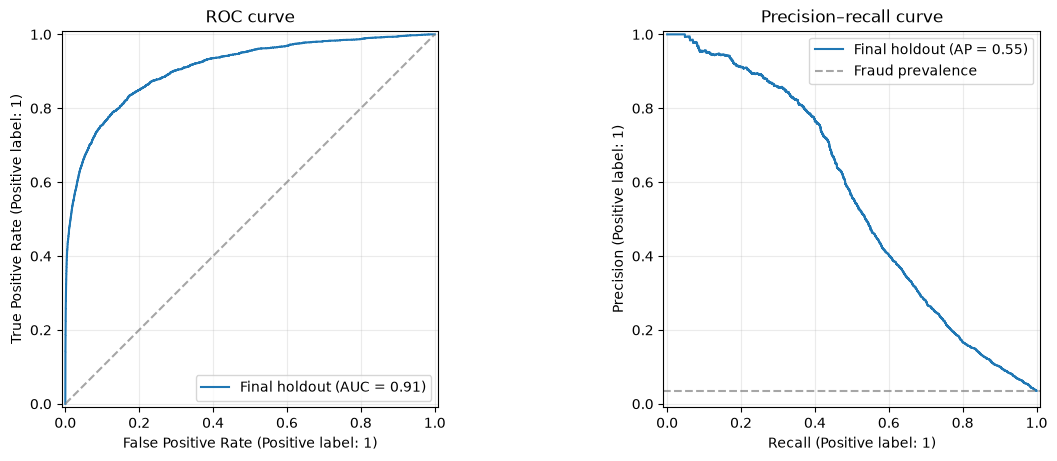

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

RocCurveDisplay.from_predictions(
    y_holdout,
    holdout_proba,
    name="Final holdout",
    ax=axes[0],
)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="grey", alpha=0.7)
axes[0].set_title("ROC curve")
axes[0].grid(alpha=0.25)

PrecisionRecallDisplay.from_predictions(
    y_holdout,
    holdout_proba,
    name="Final holdout",
    ax=axes[1],
)
axes[1].axhline(
    y_holdout.mean(),
    linestyle="--",
    color="grey",
    alpha=0.7,
    label="Fraud prevalence",
)
axes[1].set_title("Precision–recall curve")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.show()

## 6. Качество верхней части рейтинга

Посмотрим, сколько fraud попадает среди транзакций с самым высоким score.

In [11]:
ranking_rows = []
sorted_positions = np.argsort(-holdout_proba)
holdout_fraud_rate = y_holdout.mean()

for top_share in [0.01, 0.02, 0.05, 0.10]:
    top_count = int(np.ceil(len(y_holdout) * top_share))
    selected_positions = sorted_positions[:top_count]
    selected_target = y_holdout[selected_positions]

    precision_at_top = selected_target.mean()
    fraud_capture_rate = selected_target.sum() / y_holdout.sum()

    ranking_rows.append({
        "top_share": top_share,
        "transactions_flagged": top_count,
        "precision": precision_at_top,
        "fraud_capture_rate": fraud_capture_rate,
        "lift_vs_random": precision_at_top / holdout_fraud_rate,
    })

ranking_metrics = pd.DataFrame(ranking_rows)
display(ranking_metrics.round(4))

,top_share,transactions_flagged,precision,fraud_capture_rate,lift_vs_random
0,0.01,855,0.8912,0.2545,25.4301
1,0.02,1709,0.7343,0.4192,20.9537
2,0.05,4272,0.4134,0.5898,11.7955
3,0.10,8543,0.2532,0.7224,7.2244


## 7. Пороги

Таблица показывает связь между числом алертов, precision и recall. Production-порог по holdout не выбираем.

In [12]:
threshold_rows = []

for threshold in [0.05, 0.10, 0.20, 0.30, 0.50]:
    holdout_prediction = (holdout_proba >= threshold).astype("int8")
    tn, fp, fn, tp = confusion_matrix(
        y_holdout, holdout_prediction, labels=[0, 1]
    ).ravel()

    threshold_rows.append({
        "threshold": threshold,
        "alert_rate": holdout_prediction.mean(),
        "precision": precision_score(
            y_holdout, holdout_prediction, zero_division=0
        ),
        "recall": recall_score(
            y_holdout, holdout_prediction, zero_division=0
        ),
        "f1": f1_score(y_holdout, holdout_prediction, zero_division=0),
        "false_positive_rate": fp / (fp + tn),
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
    })

threshold_metrics = pd.DataFrame(threshold_rows)
display(threshold_metrics.round(4))

,threshold,alert_rate,precision,recall,f1,false_positive_rate,true_positives,false_positives,false_negatives
0,0.05,0.1034,0.2470,0.7288,0.3689,0.0807,2182,6653,812
1,0.10,0.0549,0.3892,0.6102,0.4753,0.0348,1827,2867,1167
2,0.20,0.0308,0.5653,0.4973,0.5291,0.0139,1489,1145,1505
3,0.30,0.0225,0.6873,0.4419,0.5379,0.0073,1323,602,1671
4,0.50,0.0151,0.8192,0.3540,0.4944,0.0028,1060,234,1934


## 8. Важность признаков

Gain показывает, какие признаки чаще давали полезные разбиения в деревьях. Это не доказательство причинной связи.

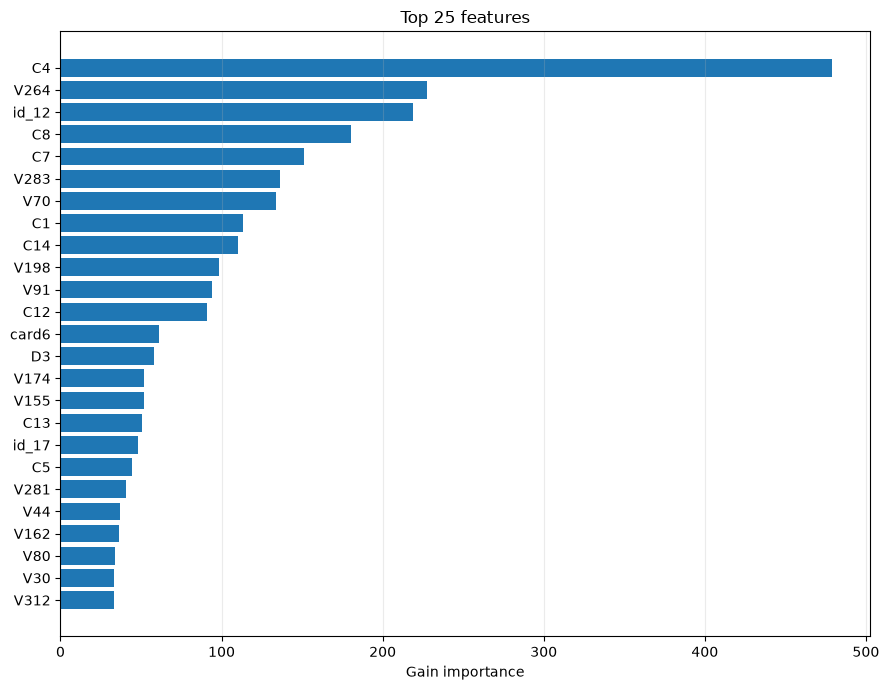

,gain
C4,478.8015
V264,227.8320
id_12,218.6146
C8,180.5328
C7,151.0550
V283,135.9773
V70,134.0845
C1,113.1749
C14,110.1356
V198,98.4599


In [13]:
gain_scores = final_model.get_booster().get_score(importance_type="gain")

gain_importance = pd.Series(
    {
        feature_names[int(feature_key[1:])]: score
        for feature_key, score in gain_scores.items()
    },
    name="gain",
).sort_values(ascending=False)

top_gain_importance = gain_importance.head(25).sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_gain_importance.index, top_gain_importance.values)
ax.set(
    xlabel="Gain importance",
    title="Top 25 features",
)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

display(gain_importance.head(25).to_frame().round(4))

In [14]:
holdout_predictions = pd.DataFrame(
    {
        "relative_day": holdout_day,
        "isFraud": y_holdout,
        "fraud_probability": holdout_proba,
    },
    index=pd.Index(holdout_index, name=ID_COLUMN),
)

display(holdout_predictions.head())

,relative_day,isFraud,fraud_probability
TransactionID,,,
3492110,153,0,0.007789
3492111,153,0,0.003729
3492112,153,0,0.004101
3492113,153,0,0.011679
3492114,153,0,0.001798


## 9. Вывод

Final holdout ROC-AUC равен 0.90913, PR-AUC — 0.55475. Это немного выше среднего результата development CV: +0.00696 ROC-AUC и +0.00437 PR-AUC.

Train ROC-AUC равен 0.96977, разрыв с holdout — 0.06065. В верхних 5% рейтинга модель находит 58.98% fraud при precision 41.34%.

Holdout подтвердил выбранную модель. Дальше обучаем её на полном train и строим Kaggle submission.